# Buổi C9: Dự án phân loại trọn vẹn, từ câu hỏi đến bản báo cáo

**Hiện trường.** Chị Hạnh nhận lệnh cuối cùng của phần C: *"Nộp cho hội đồng bệnh viện một **bản báo cáo** về việc có nên dùng mô hình hỗ trợ sàng lọc tế bào u hay không. Đừng đưa con số đẹp, hãy đưa con số thật."* Không còn bài giảng từng mô hình: ta phải **chọn mô hình, đo nó thật thà và viết kết luận có cả điểm yếu**.

Buổi này là **tổng ôn** C1 đến C8 bằng quy trình năm bước của A5, ở quy mô của một dự án thật:

1. đặt câu hỏi và chọn thước đo **trước khi** nhìn mô hình;
2. niêm phong tập thi;
3. so nhiều mô hình **công bằng**;
4. chọn mô hình và ngưỡng **chỉ trên tập học**;
5. mở tập thi **một lần**, kiểm tra theo nhóm con, và chạy **phép thử đối chứng**.

**Mindset của người làm dữ liệu:** bản báo cáo tốt không phải bản có con số cao nhất, mà là bản **người đọc ra quyết định đúng** từ đó.

**Lưu ý:** dữ liệu mẫu để học, **không dùng chẩn đoán**. Buổi này không dạy cú pháp mới, chỉ ghép những gì đã học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 1 | Câu hỏi, thước đo, mốc ngu và niêm phong tập thi |
| Chặng 2 | Sáu ứng viên, đo công bằng bằng kiểm định chéo lặp |
| Chặng 3 | Chọn mô hình: quy tắc một sai số chuẩn |
| Chặng 4 | Chỉnh núm vặn và chọn ngưỡng, vẫn chỉ trên tập học |
| Chặng 5 | Mở tập thi một lần và soi theo nhóm con |
| Chặng 6 | Phép thử đối chứng và bản báo cáo |

## Chặng 1: Câu hỏi, thước đo, mốc ngu và niêm phong tập thi

**Câu hỏi quyết định thước đo.** Mô hình báo **ác tính** thì bệnh nhân được xét nghiệm thêm; báo **lành tính** thì về nhà. Bỏ sót một ca ác tính **nặng hơn nhiều** so với báo nhầm một ca lành tính (chỉ thêm một xét nghiệm). Vậy:

- thước đo chính: **recall của ác tính** (tỉ lệ ca ác tính bị bắt) **với mục tiêu ≥ 0,98** (bỏ sót tối đa khoảng 2 trong 100 ca ác tính);
- thước đo phụ: **precision** (để biết giá của việc báo nhầm), **AUC** (chất lượng xếp hạng không phụ thuộc ngưỡng).

Ta chốt điều này **trước khi** chạy mô hình để khỏi chọn thước đo theo hướng "mô hình nào cũng đẹp".

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score, confusion_matrix
bc = load_breast_cancer(as_frame=True)
X, y = bc.data, 1 - bc.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=2026, stratify=y)
print("train:", X_train.shape, "malignant", int(y_train.sum()), f"({y_train.mean():.1%}) | test (sealed):", X_test.shape, "malignant", int(y_test.sum()))
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("dummy baseline: accuracy", round(dummy.score(X_train, y_train), 3), "| recall 0.0 | AUC 0.5")

train: (426, 30) malignant 159 (37.3%) | test (sealed): (143, 30) malignant 53
dummy baseline: accuracy 0.627 | recall 0.0 | AUC 0.5


**Giải thích từng dòng**

- `y = 1 - bc.target`: nhóm dương 1 là **ác tính** (nhóm cần bắt).
- `train_test_split(..., random_state=2026, stratify=y)`: (đã học ở A4) chia 75/25 giữ tỉ lệ nhóm. `X_test, y_test` **niêm phong**: từ giờ đến chặng 5 không đụng tới.
- `DummyClassifier(strategy="most_frequent")`: mốc ngu (C2, C8).

**Cách đọc:** tập học **426** ca (159 ác tính, 37%), tập thi niêm phong **143** ca (53 ác tính). Mốc ngu: độ đúng **0,627** (bằng tỉ lệ lành tính), recall 0. Mọi mô hình phải vượt mốc này **ở recall**, không chỉ ở độ đúng.

Số ca ác tính trong tập thi chỉ **53**: nhớ C8, kết quả cuối sẽ có khoảng không chắc chắn rộng.

**Mang về chặng 1:** chốt câu hỏi, thước đo, mốc ngu và niêm phong tập thi *trước* khi so mô hình.

## Chặng 2: Sáu ứng viên, đo công bằng bằng kiểm định chéo lặp

**Câu hỏi:** mô hình nào của phần C hợp nhất với bài toán này?

Sáu ứng viên, mỗi mô hình đứng trong một **pipeline** (chuẩn hóa nằm *bên trong* kiểm định chéo) và đo trên **cùng cách chia** (15 phần thi: 5 phần × 3 lần lặp).

In [3]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
candidates = {
    "logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "logistic C=0.1": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)),
    "k-NN k=9": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9)),
    "Gaussian NB": GaussianNB(),
    "tree depth 3": DecisionTreeClassifier(max_depth=3, random_state=0),
    "SVM rbf": make_pipeline(StandardScaler(), SVC()),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
rows = []
for name, m in candidates.items():
    r = cross_validate(m, X_train, y_train, cv=cv, scoring=["accuracy", "recall", "precision", "roc_auc"])
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in ["accuracy", "recall", "precision", "roc_auc"]}, "AUC std": r["test_roc_auc"].std()})
board = pd.DataFrame(rows).set_index("model").round(3)
print(board.sort_values("roc_auc", ascending=False).to_string())

                accuracy  recall  precision  roc_auc  AUC std
model                                                        
logistic C=0.1     0.977   0.956      0.983    0.998    0.002
logistic           0.974   0.956      0.975    0.997    0.002
SVM rbf            0.972   0.954      0.971    0.997    0.003
k-NN k=9           0.967   0.927      0.985    0.993    0.007
Gaussian NB        0.941   0.895      0.946    0.986    0.008
tree depth 3       0.929   0.891      0.919    0.931    0.047


**Giải thích từng dòng**

- `candidates = {...}`: từ điển *tên → mô hình*; mỗi mô hình cần chuẩn hóa được bọc trong `make_pipeline` (A5, B4). Cây và Naive Bayes không cần chuẩn hóa.
- `cross_validate(m, X_train, y_train, cv=cv, scoring=[...])`: **mới (gần như đã học):** như `cross_val_score` nhưng cho **nhiều thước đo một lần**. Kết quả là từ điển, khóa `test_<tên thước đo>` chứa điểm của từng phần thi.
- `**{k: r[f"test_{k}"].mean() for k in [...]}`: `**` bung từ điển nhỏ vào dòng; mỗi thước đo lấy trung bình.
- `r["test_roc_auc"].std()`: độ lệch chuẩn của AUC qua 15 phần thi: **độ bấp bênh** của ứng viên.

**Cách đọc:** xếp theo AUC từ cao xuống thấp: logistic C=0.1 (0,998), logistic (0,997), SVM rbf (0,997), k-NN k=9 (0,993), Gaussian NB (0,986), tree depth 3 (0,931). Recall (ở ngưỡng 0,5 mặc định) dao động từ 0,89 đến 0,96.

Khoảng cách giữa các ứng viên hàng đầu **nhỏ**, nằm trong độ lệch chuẩn khoảng 0,002 đến 0,047. Không thể chọn "người thắng" chỉ vì hơn vài phần nghìn: ta cần quy tắc chọn có nguyên tắc.

## Chặng 3: Chọn mô hình, quy tắc một sai số chuẩn

**Câu hỏi:** khi nhiều mô hình ngang nhau thì chọn cái nào?

**Quy tắc một sai số chuẩn (one-standard-error rule):** tìm mô hình tốt nhất, tính *sai số chuẩn* của điểm của nó (độ lệch chuẩn chia căn số phần thi), rồi chọn mô hình **đơn giản nhất** có điểm **không thấp hơn (điểm tốt nhất − một sai số chuẩn)**. Lý do: nếu chênh lệch nằm trong nhiễu thì ta ưu tiên cái dễ giải thích, ít núm vặn, ít nguy cơ quá khớp.

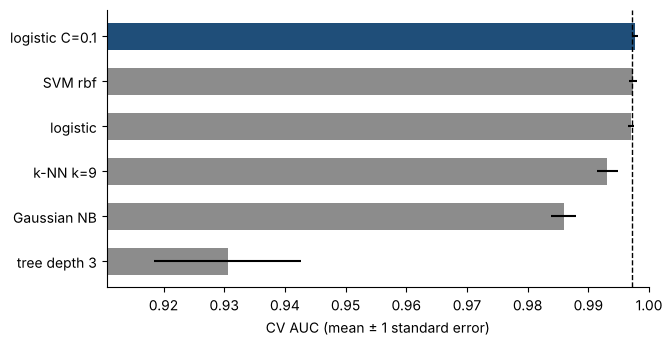

best: logistic C=0.1 0.9977 | 1-SE cutoff: 0.9973 | within cutoff: ['logistic C=0.1', 'SVM rbf'] | chosen (simplest): logistic C=0.1


In [4]:
auc_runs = {name: cross_validate(m, X_train, y_train, cv=cv, scoring="roc_auc")["test_score"] for name, m in candidates.items()}
means = pd.Series({n: s.mean() for n, s in auc_runs.items()}).sort_values(ascending=False)
best_name = means.index[0]
se = auc_runs[best_name].std() / np.sqrt(len(auc_runs[best_name]))
cutoff = means.iloc[0] - se
within = list(means[means >= cutoff].index)
simplicity_order = ["logistic C=0.1", "logistic", "tree depth 3", "Gaussian NB", "k-NN k=9", "SVM rbf"]
chosen = [n for n in simplicity_order if n in within][0]
fig, ax = plt.subplots(figsize=(7, 3.6))
ypos = range(len(means))
ax.barh(list(ypos), means.values, xerr=[auc_runs[n].std() / np.sqrt(15) for n in means.index], color=[BLUE if n == chosen else GRAY for n in means.index], height=0.6)
ax.axvline(cutoff, color="black", ls="--", lw=1); ax.set_yticks(list(ypos)); ax.set_yticklabels(means.index); ax.invert_yaxis()
ax.set_xlim(means.min() - 0.02, 1.0); ax.set_xlabel("CV AUC (mean ± 1 standard error)"); plt.show()
print("best:", best_name, round(means.iloc[0], 4), "| 1-SE cutoff:", round(cutoff, 4), "| within cutoff:", within, "| chosen (simplest):", chosen)

**Giải thích từng dòng**

- `auc_runs = {...}`: điểm AUC từng phần thi của mỗi ứng viên (15 con số mỗi mô hình).
- `se = auc_runs[best_name].std() / np.sqrt(len(...))`: **sai số chuẩn** = độ lệch chuẩn ÷ √(số phần thi). Cho biết *trung bình* sai lệch bao nhiêu.
- `within = list(means[means >= cutoff].index)`: các mô hình có điểm ≥ ngưỡng cắt.
- `simplicity_order = [...]`: thứ tự **do ta quyết** từ đơn giản (dễ giải thích, ít núm) đến phức tạp. Đây là phán đoán nghề, không phải phép tính.
- `chosen = [n for n in simplicity_order if n in within][0]`: lấy mô hình đầu tiên trong thứ tự đơn giản mà nằm trong nhóm ngang nhau.
- `ax.barh(..., xerr=[...])`: (đã học `barh` ở A3) vẽ cột ngang kèm **thanh sai số**; mô hình được chọn tô xanh.
- `ax.axvline(cutoff, ...)`: vạch đứt: ngưỡng cắt một sai số chuẩn.

**Cách đọc**

- **Con số:** tốt nhất là **logistic C=0.1** (AUC 0,998); sai số chuẩn 0,0005; ngưỡng cắt 0,997. Các mô hình trong ngưỡng: logistic C=0.1, SVM rbf. Mô hình đơn giản nhất trong số đó: **logistic C=0.1**.
- **Bức tranh:** thanh sai số của các ứng viên đầu bảng **chồng lên nhau**; thanh xanh (mô hình chọn) nằm trong nhóm đó.
- **Ý nghĩa:** ta không tuyên bố "logistic C=0.1 giỏi nhất"; ta nói "logistic C=0.1 **không kém** những mô hình phức tạp hơn mà dễ giải thích hơn", và đó là lý do chọn. Phép chọn này dựa **chỉ trên tập học**.

**Mang về chặng 3:** khi chênh lệch nằm trong nhiễu, chọn mô hình đơn giản nhất trong nhóm ngang nhau.

## Chặng 4: Chỉnh núm vặn và chọn ngưỡng, vẫn chỉ trên tập học

**Câu hỏi:** ngưỡng 0,5 có đạt mục tiêu recall ≥ 0,98 không? Nếu không thì dời đến đâu?

In [5]:
from sklearn.model_selection import GridSearchCV
final_model = candidates[chosen]
search = GridSearchCV(final_model, {final_model.steps[-1][0] + "__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}, cv=cv, scoring="roc_auc")
search.fit(X_train, y_train)
print("best C:", search.best_params_, "| CV AUC:", round(search.best_score_, 4))
tuned = search.best_estimator_
cv_pred = StratifiedKFold(5, shuffle=True, random_state=1)
s_oof = cross_val_predict(tuned, X_train, y_train, cv=cv_pred, method="predict_proba")[:, 1]
thr_grid = np.linspace(0.02, 0.9, 89)
rec_g = np.array([recall_score(y_train, s_oof >= t) for t in thr_grid])
prec_g = np.array([precision_score(y_train, s_oof >= t) for t in thr_grid])
t_star = thr_grid[rec_g >= 0.98].max()
print(f"default 0.5: recall {recall_score(y_train, s_oof >= 0.5):.3f}, precision {precision_score(y_train, s_oof >= 0.5):.3f}")
print(f"threshold {t_star:.2f} (highest still giving recall >= 0.98): recall {recall_score(y_train, s_oof >= t_star):.3f}, precision {precision_score(y_train, s_oof >= t_star):.3f}")

best C: {'logisticregression__C': 0.1} | CV AUC: 0.9977


default 0.5: recall 0.962, precision 0.987
threshold 0.41 (highest still giving recall >= 0.98): recall 0.981, precision 0.987


**Giải thích từng dòng**

- `final_model.steps[-1][0] + "__C"`: tên của bước cuối trong pipeline (`logisticregression`) nối `__C` thành tên tham số `logisticregression__C`: cách `GridSearchCV` trỏ vào *bên trong* pipeline.
- `GridSearchCV(final_model, {...}, cv=cv, scoring="roc_auc")`: (xem trước ở C6) thử bảy giá trị `C` bằng kiểm định chéo lặp **trên tập học**.
- `search.best_estimator_`: mô hình đã học lại với `C` tốt nhất.
- `cross_val_predict(tuned, ..., method="predict_proba")`: điểm out-of-fold trên **tập học** (C2, C8).
- `thr_grid[rec_g >= 0.98].max()`: ngưỡng **cao nhất** mà recall out-of-fold vẫn ≥ 0,98: nghiêm nhất có thể mà vẫn đạt mục tiêu.

**Cách đọc**

- **Con số:** `C` tốt nhất {'logisticregression__C': 0.1} (AUC kiểm định chéo 0,998). Ở ngưỡng 0,5 recall out-of-fold là **0,962** (precision 0,987); để đạt mục tiêu 0,98, ngưỡng hạ xuống **0,41**, recall **0,981** và precision **0,987**.
- **Ý nghĩa:** đạt mục tiêu bắt ca ác tính bằng cách **chấp nhận thêm báo nhầm**; đó là cái giá ta sẽ ghi vào báo cáo. Ngưỡng này được chọn *chỉ bằng tập học*: tập thi vẫn niêm phong.

**Mang về chặng 4:** chỉnh siêu tham số và ngưỡng đều bằng kiểm định chéo trên tập học; ngưỡng đi theo yêu cầu nghiệp vụ.

## Chặng 5: Mở tập thi một lần và soi theo nhóm con

**Câu hỏi:** mô hình cuối cùng làm gì trên 143 ca chưa từng thấy, và nó có đối xử đều với mọi nhóm bệnh nhân không?

Mở tập thi **một lần duy nhất**. Quyết định cuối đã chốt: mô hình `tuned`, ngưỡng `t_star`.

In [6]:
s_test = tuned.predict_proba(X_test)[:, 1]
p_test = (s_test >= t_star).astype(int)
cm = confusion_matrix(y_test, p_test)
print("confusion matrix (rows true, cols predicted):\n", cm)
print(f"TEST: recall {recall_score(y_test, p_test):.3f} | precision {precision_score(y_test, p_test):.3f} | accuracy {accuracy_score(y_test, p_test):.3f} | AUC {roc_auc_score(y_test, s_test):.3f}")
rng = np.random.RandomState(0)
idx = np.arange(len(y_test))
boot_rec = []
for _ in range(3000):
    b = rng.choice(idx, len(idx), replace=True)
    if y_test.values[b].sum() > 0:
        boot_rec.append(recall_score(y_test.values[b], p_test[b]))
lo, hi = np.percentile(boot_rec, [2.5, 97.5])
print(f"recall 95% bootstrap interval: {lo:.2f} to {hi:.2f}")
size_group = pd.qcut(X_test["mean radius"], 3, labels=["small", "medium", "large"])
sub = pd.DataFrame({"group": size_group, "true": y_test.values, "pred": p_test})
rows = []
for gname, d in sub.groupby("group", observed=True):
    rows.append({"nucleus size": gname, "cases": len(d), "malignant": int(d["true"].sum()), "missed": int(((d["true"] == 1) & (d["pred"] == 0)).sum()), "false alarms": int(((d["true"] == 0) & (d["pred"] == 1)).sum())})
print(pd.DataFrame(rows).to_string(index=False))

confusion matrix (rows true, cols predicted):
 [[89  1]
 [ 3 50]]
TEST: recall 0.943 | precision 0.980 | accuracy 0.972 | AUC 0.986


recall 95% bootstrap interval: 0.87 to 1.00
nucleus size  cases  malignant  missed  false alarms
       small     48          2       1             0
      medium     48          9       1             1
       large     47         42       1             0


**Giải thích từng dòng**

- `tuned.predict_proba(X_test)[:, 1]`: **lần đầu và duy nhất** mô hình chạm tập thi.
- `p_test = (s_test >= t_star).astype(int)`: áp ngưỡng đã chốt từ trước, không chỉnh theo kết quả.
- `for _ in range(3000): b = rng.choice(idx, len(idx), replace=True)`: (C2, C8) bootstrap: bốc lại **cả hàng** (nhãn và dự đoán đi cùng nhau) 3000 lần.
- `if y_test.values[b].sum() > 0:`: bỏ lần bốc nào tình cờ không có ca ác tính (recall vô nghĩa).
- `pd.qcut(X_test["mean radius"], 3, labels=[...])`: **mới:** `qcut` chia cột thành 3 nhóm **số ca bằng nhau** (tam phân vị): nhân nhỏ, vừa, lớn.
- `sub.groupby("group", observed=True)`: (đã học `groupby`) tính riêng cho từng nhóm con; `observed=True` chỉ để pandas khỏi cảnh báo.

**Cách đọc**

- **Con số:** trên tập thi niêm phong, recall **0,943**, precision **0,980**, độ đúng 0,972, AUC 0,986. Bỏ sót **3** ca ác tính, báo nhầm **1** ca lành tính. Khoảng tin cậy 95% của recall: **0,87 đến 1,00**.
- **So với dự kiến:** kiểm định chéo cho recall 0,981; tập thi cho 0,943. Hai con số lệch nhau là bình thường với 53 ca ác tính: **không chỉnh lại mô hình sau khi thấy kết quả này**, vì đó là bắt đầu rò rỉ.
- **Theo nhóm con:** bảng cuối chia bệnh nhân theo kích thước nhân (nhỏ, vừa, lớn). Cột `malignant` cho thấy **phần lớn ca ác tính nằm ở nhóm nhân lớn**; ở nhóm nhỏ chỉ có vài ca ác tính nên *mỗi ca bỏ sót làm tỉ lệ bỏ sót của nhóm đó vọt lên rất cao*. Với số ca nhỏ thế này, đây là **tín hiệu để điều tra tiếp** (ca ác tính nhân nhỏ có bị bỏ sót nhiều hơn không?), không phải kết luận.

**Mang về chặng 5:** mở tập thi một lần, báo cáo cả khoảng tin cậy, và soi theo nhóm con để thấy chỗ mô hình yếu.

## Chặng 6: Phép thử đối chứng và bản báo cáo

**Câu hỏi:** làm sao biết quy trình của ta không tự lừa mình?

**Phép thử đối chứng (shuffled-label control):** xáo trộn nhãn của tập học (ngắt mọi liên hệ thật giữa cột và nhãn) rồi chạy *y nguyên* quy trình. Nếu quy trình sạch, AUC phải ≈ 0,5 (đoán mò). Nếu ra cao hơn nhiều thì quy trình của ta **rò rỉ** ở đâu đó.

shuffled-label AUC over 20 repeats: mean 0.506, range 0.405 to 0.582
real-label CV AUC: 0.998


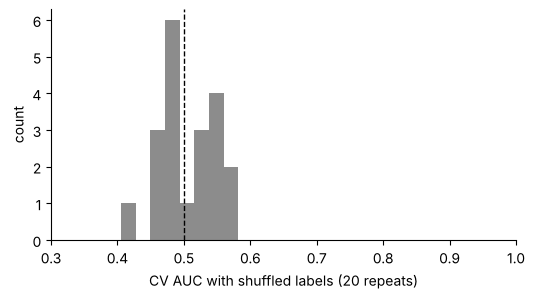

In [7]:
rng2 = np.random.RandomState(7)
null_auc = []
for _ in range(20):
    y_shuf = pd.Series(rng2.permutation(y_train.values), index=y_train.index)
    r = cross_validate(tuned, X_train, y_shuf, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="roc_auc")
    null_auc.append(r["test_score"].mean())
print(f"shuffled-label AUC over 20 repeats: mean {np.mean(null_auc):.3f}, range {np.min(null_auc):.3f} to {np.max(null_auc):.3f}")
print(f"real-label CV AUC: {search.best_score_:.3f}")
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(null_auc, bins=8, color=GRAY); ax.axvline(0.5, color="black", ls="--", lw=1)
ax.set(xlim=(0.3, 1.0), xlabel="CV AUC with shuffled labels (20 repeats)", ylabel="count"); plt.show()

**Giải thích từng dòng**

- `rng2.permutation(y_train.values)`: **xáo thứ tự** nhãn: mỗi ca nhận nhãn của một ca ngẫu nhiên khác.
- `index=y_train.index`: giữ lại chỉ số dòng để khớp với `X_train`.
- `cross_validate(tuned, X_train, y_shuf, ..., scoring="roc_auc")`: chạy cùng mô hình, cùng cách đo, nhưng với nhãn đã xáo.
- `ax.hist(null_auc, ...); ax.axvline(0.5, ...)`: biểu đồ cột phân bố 20 kết quả; vạch đứt ở 0,5 (đoán mò).

**Cách đọc:** với nhãn xáo, AUC trung bình **0,506** (từ 0,41 đến 0,58), quanh 0,5 như mong đợi, trong khi nhãn thật cho **0,998**. Quy trình **không tự khen mình**: điểm cao đến từ liên hệ thật giữa cột và nhãn, không phải từ rò rỉ. (Phép thử này không bắt được mọi lỗi, ví dụ mẫu dữ liệu lệch so với thực tế, nhưng bắt được rò rỉ trong quy trình.)

## Bản báo cáo cho hội đồng bệnh viện

**Câu hỏi.** Mô hình hỗ trợ sàng lọc tế bào u có nên dùng để *ưu tiên xét nghiệm thêm* không?

**Phương pháp.** 426 ca học, 143 ca thi niêm phong (mở một lần). Sáu mô hình so bằng kiểm định chéo lặp; chọn **logistic C=0.1** (chuẩn hóa + hồi quy logistic) theo quy tắc một sai số chuẩn. Ngưỡng dời xuống 0,41 để đạt mục tiêu bắt ≥ 98% ca ác tính trên tập học.

**Kết quả trên tập thi.** Recall 0,94 (khoảng tin cậy 95%: 0,87 đến 1,00), precision 0,98, bỏ sót 3 / 53 ca ác tính, báo nhầm 1 / 90 ca lành tính. Phép thử nhãn xáo cho AUC ≈ 0,5: quy trình sạch.

**Hạn chế (đọc kỹ).**

1. Chỉ **53** ca ác tính trong tập thi: khoảng tin cậy rộng, con số recall chỉ là *ước lượng thô*.
2. Dữ liệu từ **một nguồn** với tỉ lệ ác tính 37%. Ở bệnh viện tỉ lệ này khác (có thể thấp hơn nhiều), khiến **precision thực tế thấp hơn** nhiều so với bảng trên (nhớ C8).
3. Các cột do thiết bị đo; đổi thiết bị hoặc quy trình có thể đổi phân phối, cần **kiểm tra lại** trước khi dùng.
4. Chưa kiểm theo nhóm bệnh nhân (tuổi, nguồn gốc mẫu); bảng nhóm con chỉ gợi ý.

**Khuyến nghị.** Dùng như **công cụ ưu tiên**, không phải thay bác sĩ: mô hình báo ác tính thì bệnh nhân được *xét nghiệm thêm*; báo lành tính **không** có nghĩa là bỏ theo dõi. Chạy **thử nghiệm song song** vài tháng trên ca thật, đo lại recall, precision, trước khi đưa vào quy trình chính thức.

## Phán quyết và bài học nghề

**Phán quyết.** Mô hình đủ tốt để *thử nghiệm có kiểm soát*, chưa đủ để triển khai ngay. Một bản báo cáo trung thực **cho phép hội đồng nói "chưa"**.

**Bài học nghề của cả phần C.**

1. **Chốt thước đo theo hậu quả** trước khi so mô hình.
2. **Niêm phong tập thi**; mọi lựa chọn (mô hình, siêu tham số, ngưỡng) chỉ dùng tập học.
3. **So công bằng:** cùng cách chia, pipeline, đo nhiều lần, **báo độ bấp bênh**.
4. **Khi ngang nhau, chọn cái đơn giản.**
5. **Mở tập thi một lần**; báo cả khoảng tin cậy và điểm yếu.
6. **Phép thử đối chứng** để bắt rò rỉ trong chính quy trình.
7. **Báo cáo nói được điều mô hình chưa làm được.**

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 1 | Quy trình phân loại trọn vẹn: câu hỏi và thước đo, niêm phong thi, so công bằng, chọn, chốt ngưỡng, mở thi một lần, đối chứng, báo cáo. |
| 2 | Quy tắc một sai số chuẩn: khi nhiều mô hình ngang nhau, chọn cái đơn giản nhất. |
| 3 | Siêu tham số và ngưỡng chỉ chọn bằng kiểm định chéo trên tập học. |
| 4 | Báo cáo thật thà gồm khoảng tin cậy, điểm yếu, nhóm con và hạn chế dữ liệu. |
| 5 | Phép thử nhãn xáo kiểm tra quy trình có rò rỉ không. |
| 6 | Phán quyết tốt có thể là "chưa", kèm cách kiểm chứng tiếp. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Chọn mô hình đơn giản nhất trong nhóm ngang nhau | quy tắc một sai số chuẩn | `std / np.sqrt(n)` |
| Đo nhiều thước đo một lần | kiểm định chéo đa thước đo | `cross_validate(scoring=[...])` |
| Tìm siêu tham số bằng lưới | tìm lưới siêu tham số | `GridSearchCV` |
| Trỏ vào tham số bên trong pipeline | tên tham số lồng nhau | `tenbuoc__C` |
| Chia cột thành nhóm số ca bằng nhau | phân vị | `pd.qcut` |
| Kết quả riêng cho từng nhóm bệnh nhân | phân tích nhóm con | `groupby` |
| Xáo nhãn để thử quy trình | phép thử đối chứng | `rng.permutation(y)` |
| Tập thi chỉ mở một lần | tập thi niêm phong | `X_test, y_test` |
| Khoảng dao động của recall | khoảng tin cậy bootstrap | `np.percentile` |

**Thử thách tự làm**

1. Đổi `random_state` của lần chia 75/25 vài lần và chạy lại toàn bộ. Recall trên tập thi dao động bao nhiêu? Điều đó nói gì về việc tin một lần chia duy nhất?
2. Thêm `SVC(class_weight="balanced")` vào danh sách ứng viên. Quy tắc một sai số chuẩn còn chọn logistic không?
3. Viết lại bản báo cáo cho trường hợp tỉ lệ ác tính ở bệnh viện chỉ là 5%: ước lượng precision thực tế bằng cách giữ recall và tỉ lệ báo nhầm, rồi đổi tỉ lệ nhóm.

**Checklist năng lực** (tự tick khi làm được)

- [ ] Chốt thước đo theo hậu quả trước khi chạy mô hình.
- [ ] Niêm phong tập thi và giải thích vì sao chỉ mở một lần.
- [ ] Áp dụng quy tắc một sai số chuẩn.
- [ ] Chọn ngưỡng theo yêu cầu nghiệp vụ mà không đụng tập thi.
- [ ] Chạy phép thử nhãn xáo và đọc kết quả.
- [ ] Viết báo cáo có hạn chế và khuyến nghị thật thà.

## Phần thưởng (Tip pro): Hiệu chỉnh xác suất: đáng tin khi nói "90% ác tính"?


Mô hình báo "xác suất ác tính 0,9" nhưng trong các ca nó báo 0,9, thật sự có 90% ác tính không? Đó là **hiệu chỉnh** (calibration). Vẽ nhanh bằng `sklearn.calibration.calibration_curve` và sửa bằng `CalibratedClassifierCV` (đã gặp ở C6). Khi quyết định phụ thuộc vào *con số xác suất* (không chỉ xếp hạng), kiểm tra hiệu chỉnh nên là một dòng trong báo cáo. Phần D sẽ quay lại.